# **🃏 NEURO-SYMBOLIC AI — ASSIGNMENT 2026/2027**
## *Card Suit Game: Integrating Neural Learning and Semantic Loss* *testo in corsivo*

---

### 🎯 **1. PROJECT OBJECTIVE**

The objective of this project is to investigate how **symbolic knowledge can be integrated into neural network training through *Semantic Loss***, using the *Card Suit Game* as a controlled neuro-symbolic learning task.

Given a pair of playing card images ` (I_x, I_y) `, the model must simultaneously **recognize the suit of each card** and **predict the game outcome**. The game involves three suits — **Hearts, Clubs, and Spades** — governed by cyclic dominance rules:

- ♥ **Hearts** beats Clubs.
- ♣ **Clubs** beats Spades.
- ♠ **Spades** beats Hearts.
- Identical suits result in a **Draw**.

*Card ranks are completely disregarded.*

> **Research Question**
>
> *Can the integration of logical constraints into the neural learning objective improve prediction consistency while maintaining competitive classification accuracy?*

---

### 🧠 **2. PROPOSED METHODOLOGY**

We adopt a **comparative experimental approach**, implementing two models with the *same neural architecture, training data, and experimental conditions*. Their only difference is the **optimization objective**.

| **NEURAL BASELINE** | **NEURO-SYMBOLIC MODEL** |
|:---|:---|
| Purely supervised learning | Supervised learning + Semantic Loss |
| Three Cross Entropy terms | Three Cross Entropy + four Semantic Loss terms |
| No explicit logical constraints | Explicit logical regularization |

#### **A. Neural Baseline — Purely Supervised Learning**

The baseline learns exclusively from labeled examples, minimizing the sum of three **Cross Entropy losses**:

`L_neural = L_x + L_y + L_o`

#### **B. Neuro-Symbolic Model — Semantic Loss**

The neuro-symbolic model incorporates two categories of logical constraints:

- **Exactly-One Constraints (αEO):** exactly one suit must be assigned to each card, and exactly one game outcome must be predicted.
- **Game Rules (αRules):** the predicted outcome must be consistent with the suits of both cards and their dominance relation.

The network produces **nine output logits**, organized into three groups of three: *first card, second card, and game outcome*. Their sigmoid transformations provide the probabilities associated with the nine Boolean propositions used by Semantic Loss.

**Complete Optimization Objective**

```text
L_total = omega_1 * (L_x + L_y + L_o)
        + omega_2 * (EO_x + EO_y + EO_o)
        + omega_3 * SL_xy
```

The hyperparameters **`omega_1`, `omega_2`, and `omega_3`** control the contribution of:

- *Supervised learning* — classification performance.
- *Exactly-One constraints* — logical exclusivity of the predictions.
- *Game-rule consistency* — compatibility between card suits and game outcome.

---

### 🔬 **3. EXPERIMENTAL PROTOCOL**

The experimental investigation is structured around **five main steps**:

1. **Baseline Training:** establish the performance of the purely neural model.
2. **Neuro-Symbolic Training:** optimize the model using the complete objective function.
3. **Ablation Study:** evaluate the contribution of logical regularization by comparing the two approaches.
4. **Hyperparameter Tuning:** investigate different combinations of loss weights using the *validation set*.
5. **Final Evaluation:** compare predictive accuracy, logical constraint satisfaction, game-rule consistency, and training time on the *test set*.

Both models use **identical data partitions and card pairs** to ensure a fair experimental comparison.

The dataset is obtained from the **Cards Image Dataset – Classification (Kaggle)**, retaining only *Hearts, Clubs, and Spades*, while excluding *Diamonds and Jokers*.

Additional experiments with **20% and 50% of the training data** are retained to investigate the effect of data availability on model performance.

---

### 📊 **4. EXPECTED CONTRIBUTION**

The project aims to assess whether **Semantic Loss provides an effective mechanism for integrating symbolic knowledge into data-driven learning**.

Rather than relying exclusively on statistical patterns, the neuro-symbolic model explicitly penalizes predictions that violate the *logical structure of the game*.

The final comparison will highlight the impact of logical regularization on:

- **Classification Performance**
- **Logical Consistency**
- **Computational Efficiency**

The theoretical component will also examine the foundations of *Semantic Loss* and the implementation of logical constraints through **brute-force enumeration of Boolean assignments**.

---

*Neuro-Symbolic AI — Card Suit Game with Semantic Loss | 2026/2027*

In [1]:
!pip install -q kagglehub pandas scikit-learn matplotlib pillow

import random
import shutil
from pathlib import Path

import kagglehub
import pandas as pd
from sklearn.model_selection import train_test_split

# Reproducibility and label conventions
SEED = 42
ALLOWED_SUITS = ["hearts", "clubs", "spades"]
SUIT_TO_ID = {"hearts": 0, "clubs": 1, "spades": 2}

# Outcome order follows the assignment: {1, x, 2}
# 1 = Player 1 wins, x = Draw, 2 = Player 2 wins
OUTCOME_TO_ID = {"player1": 0, "draw": 1, "player2": 2}

print("Downloading the Kaggle card dataset...")
dataset_path = Path(kagglehub.dataset_download(
    "gpiosenka/cards-image-datasetclassification"
))
output_dir = Path("/content/cards_filtered")
print(f"Original dataset: {dataset_path}")

# Remove a previous filtered copy to avoid keeping stale or duplicate images.
if output_dir.exists():
    shutil.rmtree(output_dir)

# Keep only the three allowed suits in the original train and test folders.
image_extensions = {".jpg", ".jpeg", ".png"}
for split in ["train", "test"]:
    split_src = dataset_path / split
    split_dst = output_dir / split

    if not split_src.exists():
        raise FileNotFoundError(f"Expected dataset split not found: {split_src}")

    for suit in ALLOWED_SUITS:
        (split_dst / suit).mkdir(parents=True, exist_ok=True)

    for card_folder in split_src.iterdir():
        if not card_folder.is_dir():
            continue

        folder_name = card_folder.name.lower()

        # Assignment requirement: exclude Diamonds and Jokers.
        if "joker" in folder_name or "diamonds" in folder_name:
            continue

        target_suit = next(
            (suit for suit in ALLOWED_SUITS if suit in folder_name),
            None
        )
        if target_suit is None:
            continue

        for image_file in card_folder.iterdir():
            if image_file.is_file() and image_file.suffix.lower() in image_extensions:
                destination = split_dst / target_suit / f"{card_folder.name}_{image_file.name}"
                shutil.copy2(image_file, destination)

print(f"Filtered images saved in: {output_dir}")

# Map every pair of suits to the correct game outcome.
def determine_outcome(suit1, suit2):
    if suit1 == suit2:
        outcome = "draw"
    elif (suit1 == "hearts" and suit2 == "clubs") or \
         (suit1 == "clubs" and suit2 == "spades") or \
         (suit1 == "spades" and suit2 == "hearts"):
        outcome = "player1"
    else:
        outcome = "player2"

    return outcome, OUTCOME_TO_ID[outcome]


def create_pairs(split_dir, num_pairs=2000, seed=SEED):
    rng = random.Random(seed)
    split_dir = Path(split_dir)

    images_by_suit = {
        suit: list((split_dir / suit).glob("*"))
        for suit in ALLOWED_SUITS
    }

    # Fail early if one of the required classes was not found.
    for suit, images in images_by_suit.items():
        images_by_suit[suit] = [
            path for path in images
            if path.is_file() and path.suffix.lower() in image_extensions
        ]
        if not images_by_suit[suit]:
            raise RuntimeError(
                f"No images found for suit '{suit}' in {split_dir / suit}"
            )

    pairs = []
    for _ in range(num_pairs):
        suit1 = rng.choice(ALLOWED_SUITS)
        suit2 = rng.choice(ALLOWED_SUITS)
        img1 = rng.choice(images_by_suit[suit1])
        img2 = rng.choice(images_by_suit[suit2])
        outcome_str, outcome_id = determine_outcome(suit1, suit2)

        pairs.append({
            "img1_path": str(img1),
            "img2_path": str(img2),
            "suit1": suit1,
            "suit2": suit2,
            "outcome_str": outcome_str,
            "label": outcome_id
        })

    return pd.DataFrame(pairs)


# Generate independent, reproducible train and test pair manifests.
df_train_total = create_pairs(output_dir / "train", num_pairs=3000, seed=SEED)
df_test = create_pairs(output_dir / "test", num_pairs=1000, seed=SEED + 1)

# Reserve a fixed validation set from the training pairs.
df_train_full, df_val = train_test_split(
    df_train_total,
    train_size=0.85,
    random_state=SEED,
    stratify=df_train_total["label"]
)

# Optional smaller training subsets for data-efficiency experiments.
df_train_50, _ = train_test_split(
    df_train_full,
    train_size=0.50,
    random_state=SEED,
    stratify=df_train_full["label"]
)
df_train_20, _ = train_test_split(
    df_train_full,
    train_size=0.20,
    random_state=SEED,
    stratify=df_train_full["label"]
)

# Save all manifests.
csv_dir = Path("/content/manifests")
csv_dir.mkdir(parents=True, exist_ok=True)

manifests = {
    "train_100.csv": df_train_full,
    "train_50.csv": df_train_50,
    "train_20.csv": df_train_20,
    "val.csv": df_val,
    "test.csv": df_test,
}

for filename, dataframe in manifests.items():
    dataframe.to_csv(csv_dir / filename, index=False)

print("\n--- MANIFEST GENERATION COMPLETED ---")
for filename, dataframe in manifests.items():
    print(f"{filename}: {len(dataframe)} pairs")

print("\nOutcome label mapping:", OUTCOME_TO_ID)
print("Suit label mapping:", SUIT_TO_ID)
print(f"Manifest folder: {csv_dir}")


100%|██████████| 385M/385M [00:03<00:00, 130MB/s]

Extracting files...


Original dataset: /root/.cache/kagglehub/datasets/gpiosenka/cards-image-datasetclassification/versions/2
Filtered images saved in: /content/cards_filtered

--- MANIFEST GENERATION COMPLETED ---
train_100.csv: 2550 pairs
train_50.csv: 1275 pairs
train_20.csv: 510 pairs
val.csv: 450 pairs
test.csv: 1000 pairs

Outcome label mapping: {'player1': 0, 'draw': 1, 'player2': 2}
Suit label mapping: {'hearts': 0, 'clubs': 1, 'spades': 2}
Manifest folder: /content/manifests


**📊 Data Exploration and Class Balance Verification**


The next cell loads the generated training manifest and checks the distribution of the three outcomes. It also displays a few image pairs together with their suit labels and the expected game result. This is a data-integrity check: before training, we verify that the filtering, pair generation, and game rules have been applied correctly.

--- DATA EXPLORATION: CARD DUEL DATASET ---
Total generated games: 2550

Outcome distribution:
outcome_str
player1    818
draw       901
player2    831
Name: count, dtype: int64


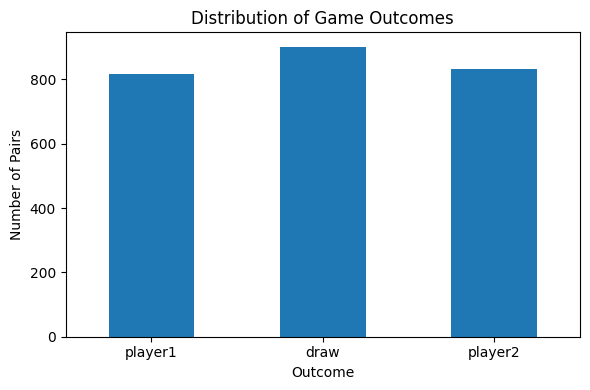

Game 1: hearts vs hearts -> draw (label=1)
Game 2: spades vs hearts -> player1 (label=0)
Game 3: clubs vs clubs -> draw (label=1)
Game 4: spades vs hearts -> player1 (label=0)


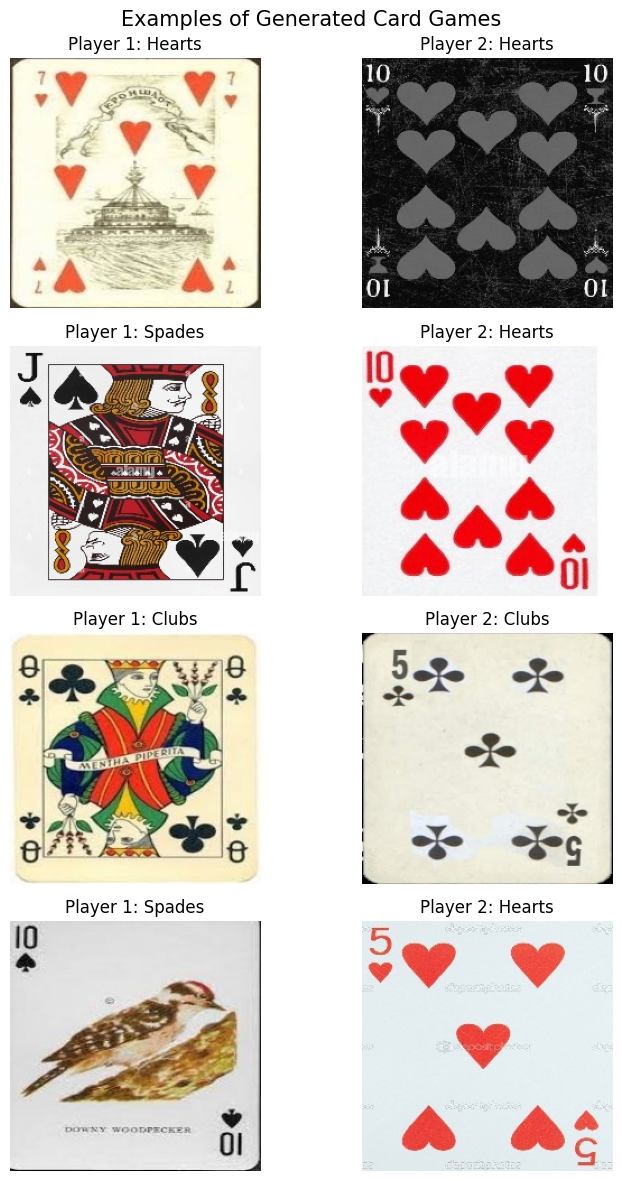

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Load the full training manifest.
csv_path = "/content/manifests/train_100.csv"
df = pd.read_csv(csv_path)

OUTCOME_ORDER = ["player1", "draw", "player2"]

print("--- DATA EXPLORATION: CARD DUEL DATASET ---")
print(f"Total generated games: {len(df)}")

# Show all three classes in the same order as the output labels: {1, x, 2}.
class_counts = df["outcome_str"].value_counts().reindex(OUTCOME_ORDER, fill_value=0)
print("\nOutcome distribution:")
print(class_counts)

fig, ax = plt.subplots(figsize=(6, 4))
class_counts.plot(kind="bar", ax=ax)
ax.set_title("Distribution of Game Outcomes")
ax.set_ylabel("Number of Pairs")
ax.set_xlabel("Outcome")
ax.set_xticklabels(class_counts.index, rotation=0)
plt.tight_layout()
plt.show()


def show_sample_matches(dataframe, num_samples=4):
    if dataframe.empty:
        print("The manifest is empty; there are no examples to display.")
        return

    num_samples = min(num_samples, len(dataframe))
    sample_df = dataframe.sample(n=num_samples, random_state=SEED).reset_index(drop=True)

    fig, axes = plt.subplots(num_samples, 2, figsize=(8, 3 * num_samples), squeeze=False)
    fig.suptitle("Examples of Generated Card Games", fontsize=15)

    for i, row in sample_df.iterrows():
        with Image.open(row["img1_path"]) as image1:
            axes[i, 0].imshow(image1.convert("RGB"))
        axes[i, 0].set_title(f"Player 1: {row['suit1'].capitalize()}")
        axes[i, 0].axis("off")

        with Image.open(row["img2_path"]) as image2:
            axes[i, 1].imshow(image2.convert("RGB"))
        axes[i, 1].set_title(f"Player 2: {row['suit2'].capitalize()}")
        axes[i, 1].axis("off")

        print(
            f"Game {i + 1}: {row['suit1']} vs {row['suit2']} "
            f"-> {row['outcome_str']} (label={row['label']})"
        )

    plt.tight_layout()
    plt.show()


show_sample_matches(df, num_samples=4)


# 📦 **DATA PREPARATION & LOADING PIPELINE**

---

### 🎯 **1. DATA PREPARATION**

Since each training sample consists of **two playing card images** and their corresponding labels, we implement a custom PyTorch `Dataset` to handle paired inputs rather than using a standard single-image dataset.

All images undergo the same preprocessing operations:

- **Resizing:** images are resized to `128 × 128` pixels.
- **Tensor Conversion:** images are converted into PyTorch tensors.
- **Normalization:** RGB channels are normalized using standard ImageNet mean and standard deviation values.

### 🗂️ **2. CUSTOM DATASET — `CardDuelDataset`**

The custom Dataset class loads the card pairs directly from the CSV manifests, applies the image transformations, and retrieves their corresponding labels.

Each sample returns **five elements**:

`(image1, image2, suit1_label, suit2_label, outcome_label)`

The label encoding is defined as follows:

| **Variable** | **Class** | **Label** |
|:---|:---|:---:|
| Card Suit | Hearts | `0` |
| Card Suit | Clubs | `1` |
| Card Suit | Spades | `2` |
| Game Outcome | Player 1 wins (`1`) | `0` |
| Game Outcome | Draw (`x`) | `1` |
| Game Outcome | Player 2 wins (`2`) | `2` |

### ⚙️ **3. DATASETS & DATALOADERS**

We instantiate separate datasets and PyTorch `DataLoader` objects for the different training configurations:

- 🟢 **`train_loader_100`:** 100% of the training data.
- 🟡 **`train_loader_50`:** 50% of the training data.
- 🔴 **`train_loader_20`:** 20% of the training data.

Additional DataLoaders are created for the **validation and test sets**.

All loaders use a **batch size of 32**. Training data is shuffled, while validation and test data are kept in a fixed order.

### 🔬 **4. EXPERIMENTAL CONSISTENCY**

The same data preparation pipeline and fixed CSV manifests are shared by the **Neural Baseline** and the **Semantic Loss Model**, ensuring that both approaches use consistent image preprocessing, labels, and data partitions.

This provides a controlled experimental setting for evaluating the contribution of **logical regularization** to neural network learning.

---

*Neuro-Symbolic AI — Card Suit Game with Semantic Loss | 2026/2027*

In [3]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import pandas as pd

# Keep the image preprocessing identical for every experiment.
IMAGE_SIZE = 128
BATCH_SIZE = 32

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class CardDuelDataset(Dataset):
    def __init__(self, csv_file, transform=None):
        self.data = pd.read_csv(csv_file)
        self.transform = transform
        self.suit_map = {"hearts": 0, "clubs": 1, "spades": 2}
        # The order is exactly {1, x, 2}.
        self.outcome_map = {"player1": 0, "draw": 1, "player2": 2}

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        with Image.open(row["img1_path"]) as image1:
            image1 = image1.convert("RGB")
        with Image.open(row["img2_path"]) as image2:
            image2 = image2.convert("RGB")

        if self.transform is not None:
            image1 = self.transform(image1)
            image2 = self.transform(image2)

        suit1_label = self.suit_map[row["suit1"]]
        suit2_label = self.suit_map[row["suit2"]]
        outcome_label = self.outcome_map[row["outcome_str"]]

        return (
            image1,
            image2,
            torch.tensor(suit1_label, dtype=torch.long),
            torch.tensor(suit2_label, dtype=torch.long),
            torch.tensor(outcome_label, dtype=torch.long)
        )


# Build one dataset for each fixed manifest.
train_dataset_100 = CardDuelDataset("/content/manifests/train_100.csv", transform)
train_dataset_50 = CardDuelDataset("/content/manifests/train_50.csv", transform)
train_dataset_20 = CardDuelDataset("/content/manifests/train_20.csv", transform)
val_dataset = CardDuelDataset("/content/manifests/val.csv", transform)
test_dataset = CardDuelDataset("/content/manifests/test.csv", transform)

# A fixed seed makes shuffling reproducible when the notebook is rerun from the top.
train_loader_100 = DataLoader(
    train_dataset_100, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=torch.cuda.is_available()
)
train_loader_50 = DataLoader(
    train_dataset_50, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=torch.cuda.is_available()
)
train_loader_20 = DataLoader(
    train_dataset_20, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=torch.cuda.is_available()
)

print("--- DATALOADERS READY ---")
print(f"Train 100%: {len(train_dataset_100)} pairs / {len(train_loader_100)} batches")
print(f"Train 50%:  {len(train_dataset_50)} pairs / {len(train_loader_50)} batches")
print(f"Train 20%:  {len(train_dataset_20)} pairs / {len(train_loader_20)} batches")
print(f"Validation: {len(val_dataset)} pairs / {len(val_loader)} batches")
print(f"Test:       {len(test_dataset)} pairs / {len(test_loader)} batches")


--- DATALOADERS READY ---
Train 100%: 2550 pairs / 80 batches
Train 50%:  1275 pairs / 40 batches
Train 20%:  510 pairs / 16 batches
Validation: 450 pairs / 15 batches
Test:       1000 pairs / 32 batches


# ⚖️ **EVALUATION STRATEGY — NEURAL BASELINE VS. SEMANTIC LOSS**

---

### 🎯 **1. COMPARATIVE EXPERIMENTAL APPROACH**

The experimental objective is to evaluate the contribution of **logical regularization** by comparing two versions of the same multi-output neural network.

Both models share the **same architecture, training data, labels, and data partitions**. The only difference is the loss function used during optimization.

| **NEURAL BASELINE** | **SEMANTIC LOSS MODEL** |
|:---|:---|
| Purely supervised learning | Neuro-symbolic learning |
| Three Cross Entropy terms | Cross Entropy + Semantic Loss |
| No explicit logical constraints | Exactly-One and game-rule constraints |

### 🧠 **2. NEURAL BASELINE — SUPERVISED LEARNING**

The baseline learns the three classification tasks exclusively from labeled examples, minimizing the sum of three standard Cross Entropy losses:

```text
L_neural = L_x + L_y + L_o
```

These terms correspond to the classification of the **first card, second card, and game outcome**, respectively.

### 🔗 **3. NEURO-SYMBOLIC MODEL — SEMANTIC REGULARIZATION**

The second model extends the supervised objective by introducing **four Semantic Loss terms** that encode the logical knowledge of the game:

- **EO_x, EO_y, EO_o:** enforce the *Exactly-One* constraint, requiring exactly one active class for each card and the game outcome.
- **SL_xy:** enforces consistency between the two card suits and the predicted game outcome according to the circular dominance rules.

The complete optimization objective is:

```text
L_total = omega_1 * (L_x + L_y + L_o)
        + omega_2 * (EO_x + EO_y + EO_o)
        + omega_3 * SL_xy
```

The hyperparameters **`omega_1`, `omega_2`, and `omega_3`** control the relative contribution of supervised learning and logical regularization.

### ⚙️ **4. SEMANTIC LOSS COMPUTATION**

The network produces nine output logits, which are processed differently according to their purpose:

- **Supervised learning:** raw logits are used with standard multi-class Cross Entropy.
- **Logical regularization:** sigmoid transformations provide nine independent Bernoulli probabilities, corresponding to the Boolean propositions used by Semantic Loss.

Using independent sigmoid probabilities is essential because the Exactly-One constraints must be learned through logical regularization rather than being automatically imposed by a three-class softmax.

To calculate the probability of satisfying each logical formula, we employ **brute-force enumeration** of all possible Boolean assignments:

`2^9 = 512 possible assignments`

The valid assignments are identified according to the formalized logical constraints, and their probabilities are combined to compute the corresponding Semantic Loss.

This approach is computationally feasible for the present problem and is explicitly permitted by the assignment. **No ASP or DeepProbLog inference engine is used.**

### 📊 **5. EVALUATION & MODEL SELECTION**

The two approaches are evaluated using the following metrics:

- **Suit Classification Accuracy:** accuracy for both card images.
- **Outcome Accuracy:** accuracy in predicting the game result.
- **Logical Constraint Satisfaction:** percentage of predictions satisfying the Exactly-One and game-rule constraints.
- **Training Time:** computational cost of model optimization.

The **validation set** is used for hyperparameter selection and model configuration, while the **test set** is reserved exclusively for the final performance comparison.

---

*Neuro-Symbolic AI — Card Suit Game with Semantic Loss | 2026/2027*